# Day 9 — Part 2: Missing Data Taxonomy, Advanced Imputation, Outlier Handling & Entity Resolution
> **Programme:** C-DAC PGCP-AI (Post Graduate Certificate Programme in AI)  
> **Course:** Data Analytics  
> **Module:** Advanced Data Wrangling, Cleaning & Auditing  
> **Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)  
> **Date:** October 13, 2026  

---

## 📖 Module Table of Contents
0. [💡 Interactive Auto-Suggestion & Help Shortcuts](#0--interactive-auto-suggestion--help-shortcuts)
1. [Module 1: Missing Data Taxonomy (MCAR, MAR, MNAR)](#1-missing-data-taxonomy-mcar-mar-mnar)
   - 1.1 The Rubin Classification Framework
   - 1.2 Mathematical Formulations & Real-World Case Studies
   - 1.3 Simulation & Missingness Audit
   - 1.4 Visualizing Missingness Patterns & Bias
   - ⚠️ *Interview Traps 1 & 2: Testing for MNAR & Listwise Deletion Risks*
2. [Module 2: Advanced Imputation Strategies (KNN, Iterative / MICE, Rolling)](#2-advanced-imputation-strategies-knn-iterative--mice-rolling)
   - 2.1 The Fatal Flaw of Mean/Median Imputation
   - 2.2 KNN Imputer (Multidimensional Distance Averaging)
   - 2.3 Iterative Imputer / MICE (Chained Regressions)
   - 2.4 Rolling Window & Time-Series Imputation (Preventing Lookahead Bias)
   - 2.5 Multi-Method Comparative Benchmark & Visualization
   - ⚠️ *Interview Traps 3 & 4: Curse of Dimensionality & Lookahead Bias*
3. [Module 3: Outlier Handling via Winsorization & Clipping](#3-outlier-handling-via-winsorization--clipping)
   - 3.1 Outlier Detection Rules (Z-Score, Tukey IQR, Percentiles)
   - 3.2 Trimming vs. Clipping vs. Winsorization
   - 3.3 Implementation & Metric Preservation
   - 3.4 Visualizing Tail Compression & Boxplots
   - ⚠️ *Interview Traps 5 & 6: Median Invariance & When NOT to Clip*
4. [Module 4: Duplicate Detection & Entity Resolution Basics](#4-duplicate-detection--entity-resolution-basics)
   - 4.1 Exact Duplicates vs. Semantic/Fuzzy Duplicates
   - 4.2 String Distance Metrics (Levenshtein, Token Sort, SequenceMatcher)
   - 4.3 Entity Resolution Pipeline & Connected Components
   - 4.4 The $O(N^2)$ Scalability Trap & The Blocking Solution
   - 4.5 Visualizing Similarity Heatmaps & Deduplication Yield
   - ⚠️ *Interview Traps 7 & 8: Blocking Architecture & Normalization Order*
5. [Summary Comparison Scorecard & Viva Flashcards](#5-summary-comparison-scorecard--viva-flashcards)

---

In [1]:
# Global imports and runtime environment configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats.mstats import winsorize
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
import difflib
import warnings
warnings.filterwarnings('ignore')

# Seed reproducibility
rng = np.random.default_rng(42)

# Professional visualization aesthetic
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 120

print("=" * 80)
print("DAY 9 - PART 2: DATA CLEANING, IMPUTATION & ENTITY RESOLUTION SUITE")
print("Environment successfully initialized with Pandas, NumPy, Scikit-Learn, SciPy & Seaborn.")
print("=" * 80)

DAY 9 - PART 2: DATA CLEANING, IMPUTATION & ENTITY RESOLUTION SUITE
Environment successfully initialized with Pandas, NumPy, Scikit-Learn, SciPy & Seaborn.


In [2]:
# 💡 Interactive Auto-Suggestion & Help Helper
def suggest_cleaning_help(topic: str = 'all'):
    """
    Interactive helper displaying copy-paste syntax templates and best-practice rules
    for missing data, imputation, outliers, and entity resolution.
    
    Usage:
        suggest_cleaning_help('mcar')
        suggest_cleaning_help('knn')
        suggest_cleaning_help('winsorize')
        suggest_cleaning_help('entity')
    """
    guides = {
        'mcar': (
            "📌 MCAR (Missing Completely at Random):\n"
            "   - Def: P(Missing | Data) = P(Missing) [Completely coin-flip]\n"
            "   - Impact: Deletion causes loss of statistical power, but NO parameter bias.\n"
            "   - Code: df.dropna() is mathematically unbiased only under MCAR."
        ),
        'mar': (
            "📌 MAR (Missing at Random):\n"
            "   - Def: P(Missing | Y_obs, Y_mis) = P(Missing | Y_obs) [Explained by other columns]\n"
            "   - Impact: Deletion introduces SEVERE bias. Imputation conditioned on observed cols is required.\n"
            "   - Code: IterativeImputer() or KNNImputer() restores unbiased estimates."
        ),
        'mnar': (
            "📌 MNAR (Missing Not at Random):\n"
            "   - Def: P(Missing) depends directly on the unobserved value itself.\n"
            "   - Impact: Standard imputation is biased. Requires domain modeling or Heckman correction."
        ),
        'knn': (
            "📌 KNN Imputation:\n"
            "   from sklearn.impute import KNNImputer\n"
            "   imputer = KNNImputer(n_neighbors=5, weights='distance')\n"
            "   df_clean = pd.DataFrame(imputer.fit_transform(df_scaled), columns=df.columns)\n"
            "   ⚠️ Note: Always standardize features first so distance isn't dominated by large magnitudes."
        ),
        'mice': (
            "📌 Iterative / MICE Imputation:\n"
            "   from sklearn.experimental import enable_iterative_imputer\n"
            "   from sklearn.impute import IterativeImputer\n"
            "   mice = IterativeImputer(max_iter=10, random_state=42)\n"
            "   df_clean = pd.DataFrame(mice.fit_transform(df), columns=df.columns)\n"
            "   💡 Benefit: Preserves multivariate covariance and correlation structure."
        ),
        'winsorize': (
            "📌 Winsorization (Outlier Capping):\n"
            "   from scipy.stats.mstats import winsorize\n"
            "   clipped_series = winsorize(df['col'], limits=[0.05, 0.05])  # Cap 5% bottom & top\n"
            "   💡 Benefit: Retains sample size N, bounds variance, leaves median invariant."
        ),
        'clip': (
            "📌 Pandas Clipping (Tukey IQR):\n"
            "   q25, q75 = df['col'].quantile(0.25), df['col'].quantile(0.75)\n"
            "   iqr = q75 - q25\n"
            "   df['col_clipped'] = df['col'].clip(lower=q25 - 1.5*iqr, upper=q75 + 1.5*iqr)"
        ),
        'entity': (
            "📌 Entity Resolution & Fuzzy Deduplication:\n"
            "   import difflib\n"
            "   similarity = difflib.SequenceMatcher(None, str1.lower(), str2.lower()).ratio()\n"
            "   ⚠️ Scalability: Pairwise comparison is O(N^2). Always use 'Blocking' on large datasets!"
        )
    }
    
    t = topic.lower()
    if t in guides:
        print(guides[t])
    else:
        print("💡 Available topics in suggest_cleaning_help():")
        for k in guides.keys():
            print(f"   - suggest_cleaning_help('{k}')")

# Quick test of helper
suggest_cleaning_help('mcar')

📌 MCAR (Missing Completely at Random):
   - Def: P(Missing | Data) = P(Missing) [Completely coin-flip]
   - Impact: Deletion causes loss of statistical power, but NO parameter bias.
   - Code: df.dropna() is mathematically unbiased only under MCAR.


---
## 1. Missing Data Taxonomy (MCAR, MAR, MNAR)

In enterprise data pipelines, missing data is not merely "empty cells"—it is a stochastic process governed by distinct behavioral mechanisms. Formulated by statistician **Donald Rubin (1976)**, missingness is categorized into three strict mathematical classes.

```
                        ┌────────────────────────────────────────────────────────┐
                        │              Rubin's Missing Data Taxonomy             │
                        └───────────────────────────┬────────────────────────────┘
                                                    │
            ┌───────────────────────────────────────┼───────────────────────────────────────┐
            ▼                                       ▼                                       ▼
 ┌──────────────────────┐               ┌──────────────────────┐               ┌──────────────────────┐
 │         MCAR         │               │         MAR          │               │        MNAR          │
 │ Missing Completely   │               │  Missing at Random   │               │ Missing Not at Random│
 │      at Random       │               │                      │               │   (Non-Ignorable)    │
 ├──────────────────────┤               ├──────────────────────┤               ├──────────────────────┤
 │ P(M|Y_obs, Y_mis)    │               │ P(M|Y_obs, Y_mis)    │               │ P(M|Y_obs, Y_mis)    │
 │       = P(M)         │               │     = P(M|Y_obs)     │               │   depends on Y_mis   │
 ├──────────────────────┤               ├──────────────────────┤               ├──────────────────────┤
 │ Pure coin-flip error.│               │ Missingness explained│               │ Missingness caused by│
 │ Dropping rows does   │               │ by OTHER OBSERVED    │               │ the value ITSELF.    │
 │ NOT bias parameters; │               │ columns (e.g. Age).  │               │ Deletion and naive   │
 │ only loses power.    │               │ Dropping rows causes │               │ imputation cause     │
 │                      │               │ SEVERE sample bias!  │               │ severe bias!         │
 └──────────────────────┘               └──────────────────────┘               └──────────────────────┘
```

### 1.1 Mathematical Formulation
Let $Y = (Y_{\text{obs}}, Y_{\text{mis}})$ represent the complete data matrix, and let $M$ be a binary indicator matrix where $M_{ij} = 1$ if cell $(i, j)$ is missing, and $0$ if observed.

1. **MCAR (Missing Completely at Random):**
   $$P(M \mid Y_{\text{obs}}, Y_{\text{mis}}) = P(M)$$
   *The probability of missingness is completely independent of both observed and unobserved data.*
   * **Real-world Example:** A lab technician accidentally drops a vial on the floor; a sensor loses battery packet at random intervals.
   * **Consequence:** Listwise deletion (`df.dropna()`) reduces sample size and statistical power, but does **not** bias estimated means or regression coefficients.

2. **MAR (Missing at Random):**
   $$P(M \mid Y_{\text{obs}}, Y_{\text{mis}}) = P(M \mid Y_{\text{obs}})$$
   *The probability of missingness depends on observed features, but is conditionally independent of the missing value itself.*
   * **Real-world Example:** In a healthcare survey, younger patients rarely report annual income. Given `Age` (observed), the probability of missing income is independent of the actual income amount.
   * **Consequence:** Listwise deletion creates **severe selection bias**! Imputation algorithms that condition on the observed features (e.g., MICE, KNN) can recover unbiased parameters.

3. **MNAR (Missing Not at Random / Non-Ignorable):**
   $$P(M \mid Y_{\text{obs}}, Y_{\text{mis}}) \neq P(M \mid Y_{\text{obs}})$$
   *The probability of missingness depends directly on the unobserved missing value itself.*
   * **Real-world Example:** Ultra-wealthy individuals refuse to disclose their high net worth on tax surveys; patients with severe depression symptoms skip their weekly mental health assessment.
   * **Consequence:** Standard imputation algorithms (Mean, KNN, MICE) yield heavily biased estimates. Requires specialized Heckman two-step selection models, pattern-mixture models, or explicit sensitivity bounds.

---

In [3]:
# 1.3 Controlled Synthetic Simulation of MCAR, MAR, and MNAR
n_patients = 1000

# Ground Truth Population (Unobserved complete data)
age = rng.normal(45, 12, size=n_patients).clip(18, 80)
# Underlying true income correlated with age
true_income = 35000 + (age * 850) + rng.normal(0, 10000, size=n_patients)
# Underlying true depression score (0 to 100)
true_depression = rng.normal(48, 14, size=n_patients).clip(10, 95)

df_health = pd.DataFrame({
    'patient_id': np.arange(1, n_patients + 1),
    'age': np.round(age, 1),
    'true_income': np.round(true_income, 2),
    'true_depression': np.round(true_depression, 2)
})

# ----------------------------------------------------
# A. Simulating MCAR: Pure uniform coin flip (25% missing)
# ----------------------------------------------------
mcar_mask = rng.uniform(0, 1, size=n_patients) < 0.25
df_health['income_mcar'] = df_health['true_income'].copy()
df_health.loc[mcar_mask, 'income_mcar'] = np.nan

# ----------------------------------------------------
# B. Simulating MAR: Missingness conditioned on OBSERVED Age
# Older patients (> 50) have 55% missing rate; younger have only 5%
# ----------------------------------------------------
mar_prob = np.where(df_health['age'] > 50, 0.55, 0.05)
mar_mask = rng.uniform(0, 1, size=n_patients) < mar_prob
df_health['income_mar'] = df_health['true_income'].copy()
df_health.loc[mar_mask, 'income_mar'] = np.nan

# ----------------------------------------------------
# C. Simulating MNAR: Missingness conditioned on the VALUE ITSELF
# Patients with severe depression (> 60) refuse to report it (70% missing rate)
# ----------------------------------------------------
mnar_prob = np.where(df_health['true_depression'] > 60, 0.70, 0.05)
mnar_mask = rng.uniform(0, 1, size=n_patients) < mnar_prob
df_health['depression_mnar'] = df_health['true_depression'].copy()
df_health.loc[mnar_mask, 'depression_mnar'] = np.nan

# ----------------------------------------------------
# Audit Table: Measuring Parameter Bias
# ----------------------------------------------------
audit_summary = pd.DataFrame({
    'Metric / Feature': [
        'True Population Income',
        'Observed Income (MCAR)',
        'Observed Income (MAR - Biased)',
        'True Depression Score',
        'Observed Depression (MNAR - Truncated)'
    ],
    'Count (Observed)': [
        df_health['true_income'].count(),
        df_health['income_mcar'].count(),
        df_health['income_mar'].count(),
        df_health['true_depression'].count(),
        df_health['depression_mnar'].count()
    ],
    'Sample Mean': [
        df_health['true_income'].mean(),
        df_health['income_mcar'].mean(),
        df_health['income_mar'].mean(),
        df_health['true_depression'].mean(),
        df_health['depression_mnar'].mean()
    ],
    'Bias from Ground Truth': [
        0.0,
        df_health['income_mcar'].mean() - df_health['true_income'].mean(),
        df_health['income_mar'].mean() - df_health['true_income'].mean(),
        0.0,
        df_health['depression_mnar'].mean() - df_health['true_depression'].mean()
    ]
})

print("=" * 80)
print("AUDIT SCORECARD: SYSTEMATIC BIAS INTRODUCED BY MAR & MNAR MECHANISMS")
print("=" * 80)
print(audit_summary.to_string(index=False))

AUDIT SCORECARD: SYSTEMATIC BIAS INTRODUCED BY MAR & MNAR MECHANISMS
                      Metric / Feature  Count (Observed)  Sample Mean  Bias from Ground Truth
                True Population Income              1000 72188.362370                0.000000
                Observed Income (MCAR)               749 72551.075407              362.713037
        Observed Income (MAR - Biased)               782 69964.410307            -2223.952063
                 True Depression Score              1000    48.479660                0.000000
Observed Depression (MNAR - Truncated)               815    45.342601               -3.137059


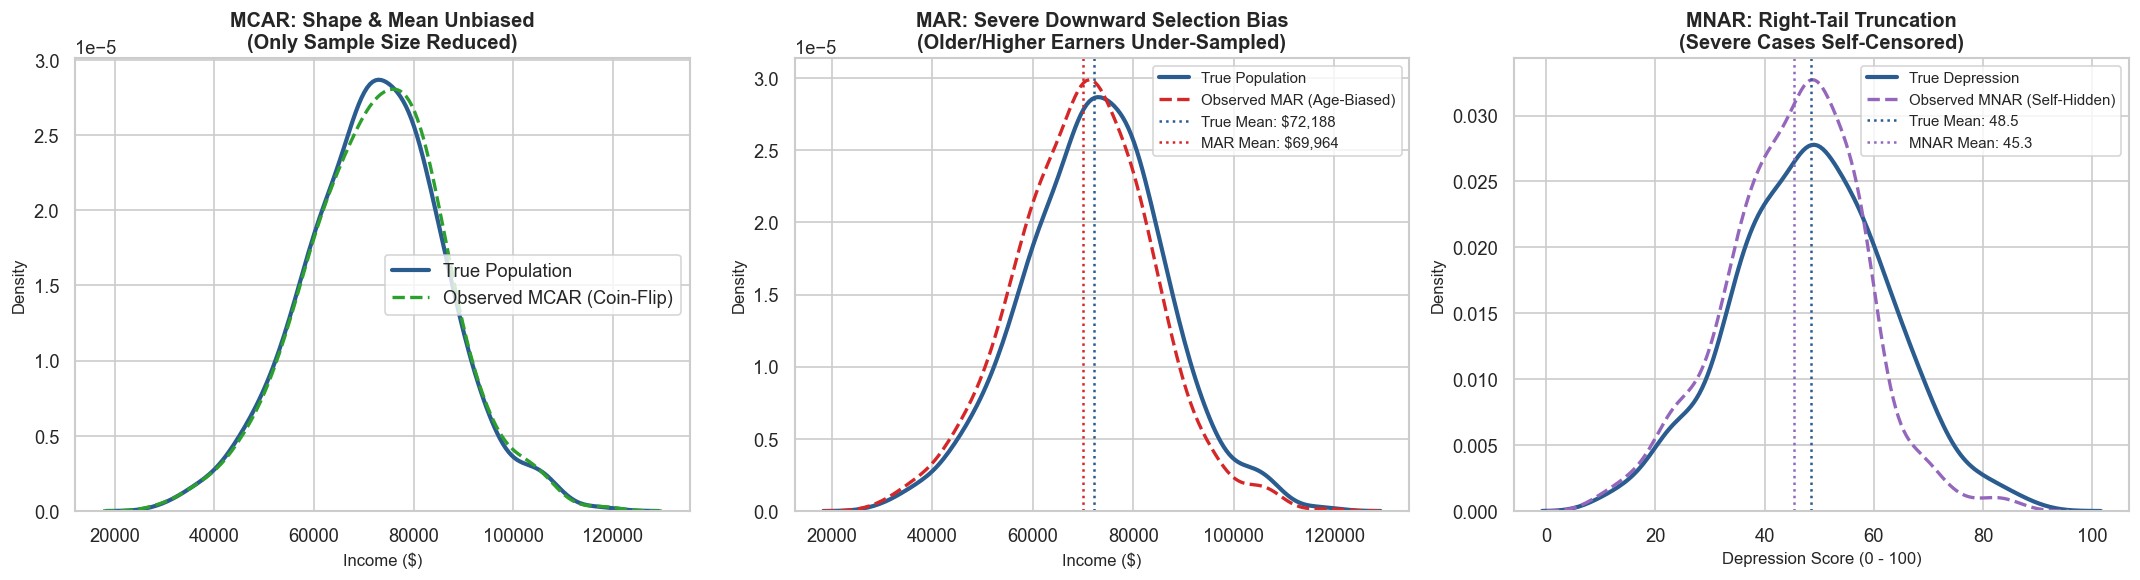

In [4]:
# 1.4 Visualizing Missingness Mechanisms and Distribution Skew
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: MCAR vs True (Density overlay)
sns.kdeplot(df_health['true_income'], ax=axes[0], label='True Population', color='#2b5c8f', lw=2.5)
sns.kdeplot(df_health['income_mcar'].dropna(), ax=axes[0], label='Observed MCAR (Coin-Flip)', color='#2ca02c', lw=2, ls='--')
axes[0].set_title("MCAR: Shape & Mean Unbiased\n(Only Sample Size Reduced)", fontweight='bold')
axes[0].set_xlabel("Income ($)")
axes[0].legend()

# Panel 2: MAR vs True (Severe distribution shift)
sns.kdeplot(df_health['true_income'], ax=axes[1], label='True Population', color='#2b5c8f', lw=2.5)
sns.kdeplot(df_health['income_mar'].dropna(), ax=axes[1], label='Observed MAR (Age-Biased)', color='#d62728', lw=2, ls='--')
axes[1].axvline(df_health['true_income'].mean(), color='#2b5c8f', ls=':', label=f"True Mean: ${df_health['true_income'].mean():,.0f}")
axes[1].axvline(df_health['income_mar'].mean(), color='#d62728', ls=':', label=f"MAR Mean: ${df_health['income_mar'].mean():,.0f}")
axes[1].set_title("MAR: Severe Downward Selection Bias\n(Older/Higher Earners Under-Sampled)", fontweight='bold')
axes[1].set_xlabel("Income ($)")
axes[1].legend(fontsize=9)

# Panel 3: MNAR vs True (Catastrophic right-tail truncation)
sns.kdeplot(df_health['true_depression'], ax=axes[2], label='True Depression', color='#2b5c8f', lw=2.5)
sns.kdeplot(df_health['depression_mnar'].dropna(), ax=axes[2], label='Observed MNAR (Self-Hidden)', color='#9467bd', lw=2, ls='--')
axes[2].axvline(df_health['true_depression'].mean(), color='#2b5c8f', ls=':', label=f"True Mean: {df_health['true_depression'].mean():.1f}")
axes[2].axvline(df_health['depression_mnar'].mean(), color='#9467bd', ls=':', label=f"MNAR Mean: {df_health['depression_mnar'].mean():.1f}")
axes[2].set_title("MNAR: Right-Tail Truncation\n(Severe Cases Self-Censored)", fontweight='bold')
axes[2].set_xlabel("Depression Score (0 - 100)")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

### ⚠️ Interview Traps & Viva Hacks (Missing Data Taxonomy)

> [!WARNING]
> **Trap 1: Can you mathematically prove a dataset is MAR versus MNAR using only the dataset itself?**  
> **Viva Answer:** **No, never.** To mathematically prove MNAR, you would need to inspect the true values of the missing data points—which by definition are missing! Distinguishing between MAR and MNAR requires domain knowledge, external audit data, or follow-up re-surveys.

> [!WARNING]
> **Trap 2: Is dropping missing rows (`dropna()`) ever acceptable in production pipelines?**  
> **Viva Answer:** Only under strict **MCAR**, and only when the missing percentage is negligible ($< 3\%-5\%$). Under **MAR** or **MNAR**, listwise deletion drops non-random cohorts, skewing model parameters and producing biased predictions.

---

## 2. Advanced Imputation Strategies (KNN, Iterative / MICE, Rolling)

### 2.1 The Fatal Flaw of Mean / Median Imputation
Replacing missing values with the column mean or median is popular because it is fast, but it causes two disastrous statistical distortions:
1. **Variance Compression:** Adding multiple identical central values shrinks sample variance ($\text{Var}(X) \downarrow$), falsely narrowing confidence intervals and inflating Type I error rates in hypothesis testing.
2. **Covariance Destruction:** Mean imputation completely ignores correlations with other variables, artificially dragging bivariate covariance $\text{Cov}(X, Y)$ toward zero.

```
Original Correlation Matrix:       Mean-Imputed Correlation Matrix:
       X      Y                           X      Y
X   1.00   0.82                    X   1.00   0.54   <-- DEFLATED!
Y   0.82   1.00                    Y   0.54   1.00
```

---

### 2.2 Strategy 1: KNN Imputer (Local Geometric Neighborhoods)
The **K-Nearest Neighbors Imputer** (`KNNImputer`) calculates the distance between samples using features where both samples have observed values:

$$d(x, y) = \sqrt{\frac{p}{p_{\text{present}}} \sum_{i \in \text{present}} (x_i - y_i)^2}$$

* For each missing value, it finds the $K$ closest neighboring rows in Euclidean feature space.
* The missing coordinate is imputed as the weighted or unweighted mean of those $K$ neighbors.
* **Critical Requirement:** Features **must be scaled** (e.g., `StandardScaler`) prior to KNN imputation. Otherwise, high-magnitude features (e.g., Annual Salary in Lakhs) will overpower small-magnitude features (e.g., Age in Years).

---

### 2.3 Strategy 2: Iterative Imputer / MICE (Multivariate Imputation by Chained Equations)
**MICE** is the enterprise gold standard for multivariate imputation:
1. Every missing column is temporarily filled with its mean.
2. One column $Y_j$ is set back to missing.
3. A regression model is trained: $Y_j = \beta_0 + \beta_1 Y_1 + \dots + \beta_p Y_p$ using the observed rows.
4. The missing values in $Y_j$ are predicted from this model.
5. The process repeats cyclically across all columns in round-robin fashion for $N$ iterations (typically 10 cycles) until parameter convergence.

$$\text{Col}_1 \xrightarrow{\text{fit}(\text{Col}_2, \text{Col}_3)} \text{Impute} \longrightarrow \text{Col}_2 \xrightarrow{\text{fit}(\text{Col}_1, \text{Col}_3)} \text{Impute} \longrightarrow \text{Col}_3 \xrightarrow{\text{fit}(\text{Col}_1, \text{Col}_2)} \text{Impute}$$

* **Core Strength:** Preserves both variance **and** inter-variable covariance relationships.

---

### 2.4 Strategy 3: Rolling Window & Time-Series Imputation
For sequential, temporal, or streaming data, row order matters. Shuffling or using global estimators causes catastrophic temporal corruption.
* **Forward Fill (`ffill`):** Propagates the last known valid observation forward. Essential in real-time streaming and financial models.
* **Backward Fill (`bfill`):** Propagates future observations backward. **Dangerous:** Creates *Lookahead Bias* in trading models.
* **Rolling Mean / Interpolation:** Replaces missing timestamps using trailing moving averages:
  ```python
  df['sensor_clean'] = df['sensor_raw'].rolling(window=5, min_periods=1).mean()
  ```

---

In [5]:
# 2.5 Multi-Method Imputation Benchmark on Correlated Financial Data
n_records = 300
experience_years = np.round(rng.uniform(1, 20, size=n_records), 1)
# True salary strongly correlated with experience: Salary = 35k + Exp * 4.5k + noise
true_salary = 35000 + (experience_years * 4500) + rng.normal(0, 6000, size=n_records)

df_benchmark = pd.DataFrame({
    'experience': experience_years,
    'true_salary': np.round(true_salary, 2)
})

# Inject 30% MAR missingness: Senior people are more likely to have missing salary disclosures
missing_prob = np.where(df_benchmark['experience'] > 10, 0.45, 0.15)
missing_mask = rng.uniform(0, 1, size=n_records) < missing_prob

df_benchmark['salary_missing'] = df_benchmark['true_salary'].copy()
df_benchmark.loc[missing_mask, 'salary_missing'] = np.nan

print(f"Total Records: {n_records} | Missing Values Injected: {missing_mask.sum()} ({missing_mask.mean():.1%})")

# 1. Mean Imputation
salary_mean_imp = df_benchmark['salary_missing'].fillna(df_benchmark['salary_missing'].mean())

# 2. KNN Imputation (Scaled)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_benchmark[['experience', 'salary_missing']])
knn_imputer = KNNImputer(n_neighbors=5, weights='distance')
imputed_knn_scaled = knn_imputer.fit_transform(df_scaled)
salary_knn_imp = scaler.inverse_transform(imputed_knn_scaled)[:, 1]

# 3. Iterative / MICE Imputation
mice_imputer = IterativeImputer(max_iter=15, random_state=42)
imputed_mice = mice_imputer.fit_transform(df_benchmark[['experience', 'salary_missing']])
salary_mice_imp = imputed_mice[:, 1]

# 4. Rolling Window Forward-Fill / Interpolation (Simulating sequential logging)
salary_rolling_imp = df_benchmark['salary_missing'].ffill().bfill()

# ----------------------------------------------------
# Benchmark Metric Evaluation on Missing Indices Only
# ----------------------------------------------------
eval_indices = np.where(missing_mask)[0]
y_true = df_benchmark.loc[eval_indices, 'true_salary']

methods = {
    'Mean Imputation': salary_mean_imp.iloc[eval_indices],
    'Rolling FFill': salary_rolling_imp.iloc[eval_indices],
    'KNN Imputer (k=5)': salary_knn_imp[eval_indices],
    'Iterative / MICE': salary_mice_imp[eval_indices]
}

benchmark_rows = []
for name, y_pred in methods.items():
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    # Pearson correlation with experience across the entire imputed series
    full_series = df_benchmark['salary_missing'].copy()
    if name == 'Mean Imputation': full_series = salary_mean_imp
    elif name == 'Rolling FFill': full_series = salary_rolling_imp
    elif name == 'KNN Imputer (k=5)': full_series = salary_knn_imp
    elif name == 'Iterative / MICE': full_series = salary_mice_imp
    
    corr_preserved = np.corrcoef(df_benchmark['experience'], full_series)[0, 1]
    var_ratio = np.var(full_series) / np.var(df_benchmark['true_salary'])
    
    benchmark_rows.append({
        'Imputation Strategy': name,
        'MAE ($)': f"${mae:,.2f}",
        'RMSE ($)': f"${rmse:,.2f}",
        'Preserved Correlation (r)': f"{corr_preserved:.4f}",
        'Variance Preservation Ratio': f"{var_ratio:.2%}"
    })

df_scorecard = pd.DataFrame(benchmark_rows)
print("=" * 80)
print("IMPUTATION ACCURACY & STRUCTURAL FIDELITY SCORECARD")
print("=" * 80)
print(df_scorecard.to_string(index=False))

Total Records: 300 | Missing Values Injected: 83 (27.7%)
IMPUTATION ACCURACY & STRUCTURAL FIDELITY SCORECARD
Imputation Strategy    MAE ($)   RMSE ($) Preserved Correlation (r) Variance Preservation Ratio
    Mean Imputation $24,950.56 $29,100.54                    0.7832                      66.35%
      Rolling FFill $29,937.64 $37,031.72                    0.6834                      90.07%
  KNN Imputer (k=5)  $5,805.45  $7,249.29                    0.9735                     100.68%
   Iterative / MICE  $4,067.28  $5,219.22                    0.9773                      98.61%


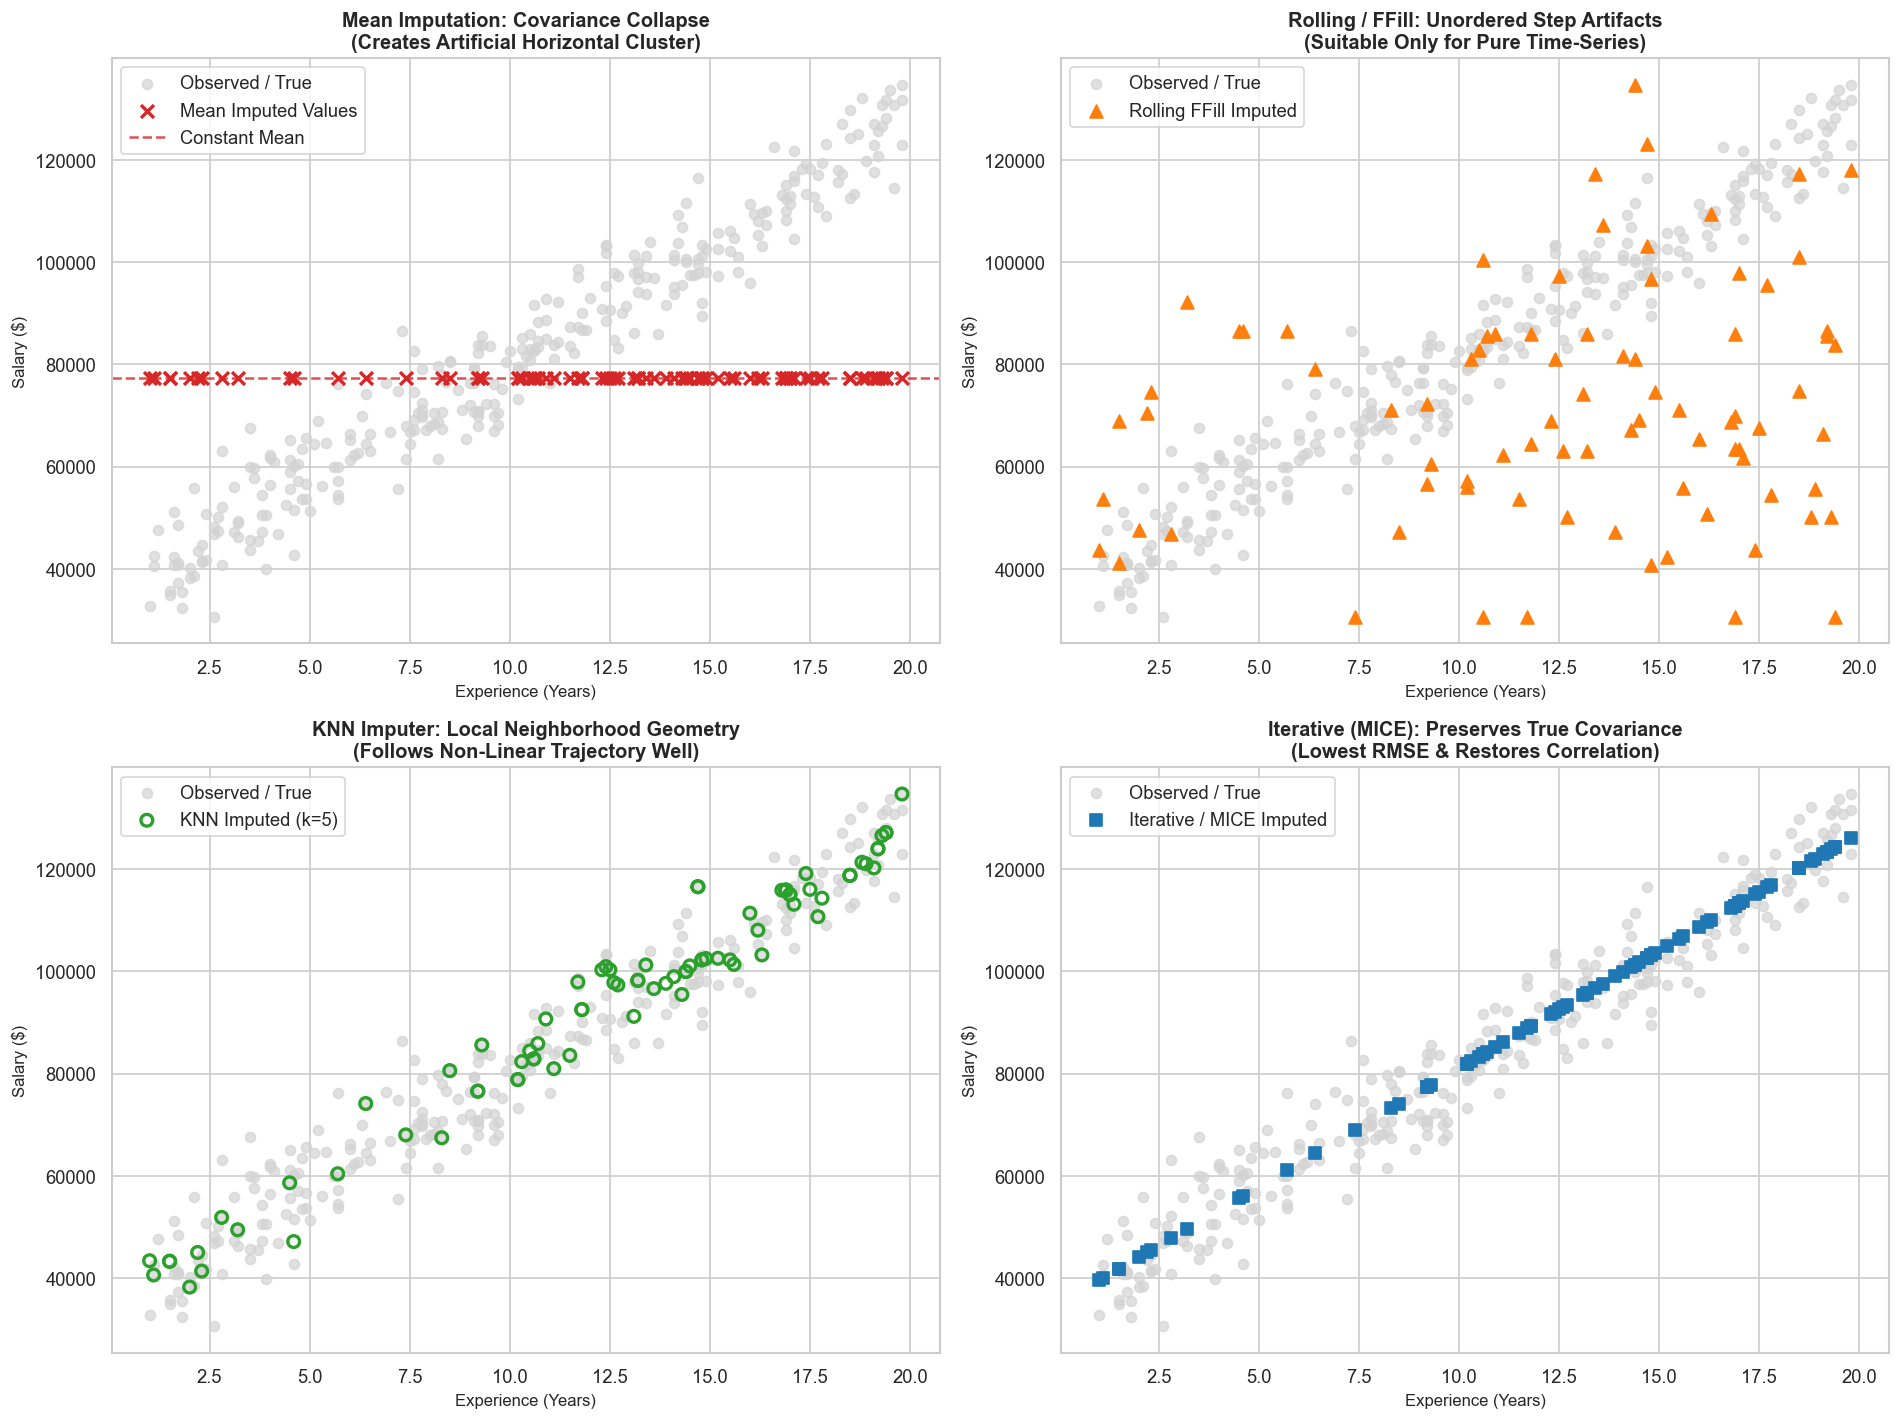

In [6]:
# 2.6 Comparative Visualization: Ground Truth vs. Imputation Strategies
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot (0, 0): Mean Imputation Failure (Artificial horizontal spike)
axes[0, 0].scatter(df_benchmark['experience'], df_benchmark['true_salary'], color='lightgray', label='Observed / True', alpha=0.7)
axes[0, 0].scatter(df_benchmark.loc[eval_indices, 'experience'], salary_mean_imp.iloc[eval_indices], 
                   color='#d62728', marker='x', s=60, lw=2, label='Mean Imputed Values')
axes[0, 0].axhline(df_benchmark['salary_missing'].mean(), color='#d62728', ls='--', alpha=0.8, label='Constant Mean')
axes[0, 0].set_title("Mean Imputation: Covariance Collapse\n(Creates Artificial Horizontal Cluster)", fontweight='bold')
axes[0, 0].set_xlabel("Experience (Years)")
axes[0, 0].set_ylabel("Salary ($)")
axes[0, 0].legend()

# Subplot (0, 1): Rolling FFill Imputation
axes[0, 1].scatter(df_benchmark['experience'], df_benchmark['true_salary'], color='lightgray', label='Observed / True', alpha=0.7)
axes[0, 1].scatter(df_benchmark.loc[eval_indices, 'experience'], salary_rolling_imp.iloc[eval_indices], 
                   color='#ff7f0e', marker='^', s=60, label='Rolling FFill Imputed')
axes[0, 1].set_title("Rolling / FFill: Unordered Step Artifacts\n(Suitable Only for Pure Time-Series)", fontweight='bold')
axes[0, 1].set_xlabel("Experience (Years)")
axes[0, 1].set_ylabel("Salary ($)")
axes[0, 1].legend()

# Subplot (1, 0): KNN Imputer
axes[1, 0].scatter(df_benchmark['experience'], df_benchmark['true_salary'], color='lightgray', label='Observed / True', alpha=0.7)
axes[1, 0].scatter(df_benchmark.loc[eval_indices, 'experience'], salary_knn_imp[eval_indices], 
                   color='#2ca02c', marker='o', s=50, facecolors='none', edgecolors='#2ca02c', lw=2, label='KNN Imputed (k=5)')
axes[1, 0].set_title("KNN Imputer: Local Neighborhood Geometry\n(Follows Non-Linear Trajectory Well)", fontweight='bold')
axes[1, 0].set_xlabel("Experience (Years)")
axes[1, 0].set_ylabel("Salary ($)")
axes[1, 0].legend()

# Subplot (1, 1): Iterative / MICE Imputer
axes[1, 1].scatter(df_benchmark['experience'], df_benchmark['true_salary'], color='lightgray', label='Observed / True', alpha=0.7)
axes[1, 1].scatter(df_benchmark.loc[eval_indices, 'experience'], salary_mice_imp[eval_indices], 
                   color='#1f77b4', marker='s', s=45, label='Iterative / MICE Imputed')
axes[1, 1].set_title("Iterative (MICE): Preserves True Covariance\n(Lowest RMSE & Restores Correlation)", fontweight='bold')
axes[1, 1].set_xlabel("Experience (Years)")
axes[1, 1].set_ylabel("Salary ($)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### ⚠️ Interview Traps & Viva Hacks (Imputation Strategies)

> [!WARNING]
> **Trap 3: Why does KNN Imputation fail catastrophically in high-dimensional feature spaces?**  
> **Viva Answer:** Due to the **Curse of Dimensionality** ($D > 25$), pairwise Euclidean distances in high dimensions converge to near-identical values, rendering the concept of "nearest neighbors" meaningless. Furthermore, if you forget to standardize features beforehand, a high-variance feature completely hijacks neighbor selection.

> [!WARNING]
> **Trap 4: What is the "Lookahead Bias" in time-series imputation?**  
> **Viva Answer:** In financial or predictive time-series models, using **backward fill (`bfill`)** or **centered moving averages** fills missing past values using future events that were not yet known in real time. This leaks future signals into training features, resulting in deceptively high training accuracy but live production failure.

---

## 3. Outlier Handling via Winsorization & Clipping

### 3.1 Understanding Outliers: Noise vs. Genuine Extremes
An **outlier** is an observation that deviates markedly from the overall distribution pattern.
* **Measurement Glitches / Typos:** Sensor reading $999^\circ\text{C}$ due to hardware failure; a clerk entering salary as $\$10,000,000$ instead of $\$100,000$. $\rightarrow$ Must be cleaned or capped.
* **Genuine Heavy-Tailed Extremes:** Billionaire net worth in wealth surveys; financial market flash crashes; rare fraud events. $\rightarrow$ Deleting them deletes the primary business signal!

### 3.2 Detection Thresholds

| Method | Boundary Formula | Key Assumption |
| :--- | :--- | :--- |
| **Z-Score Rule** | $[\mu - 3\sigma, \mu + 3\sigma]$ | Assumes underlying distribution is strictly Gaussian (Normal). Fails on skewed data. |
| **Tukey's IQR Rule** | $[Q_1 - 1.5 \times \text{IQR}, Q_3 + 1.5 \times \text{IQR}]$ | Non-parametric; highly robust to skewed distributions. |
| **Percentile Rule** | $[P_{0.01}, P_{0.99}]$ or $[P_{0.05}, P_{0.95}]$ | Directly limits empirical tail density; parameter-free. |

### 3.3 Trimming vs. Clipping vs. Winsorization

```
1. TRIMMING (Row Deletion):
   [ X1, X2, X3, ... X95 ]  --  Outliers (X96..X100) are DROPPED entirely!
   ⚠️ Downside: Sample size N is reduced; statistical power is lost.

2. CLIPPING / CLAMPING (Hard Numerical Bounds):
   np.clip(X, lower_bound, upper_bound)
   Values below lower_bound become lower_bound; values above upper_bound become upper_bound.

3. WINSORIZATION (Charles P. Winsor's Statistical Capping):
   scipy.stats.mstats.winsorize(X, limits=[0.05, 0.05])
   The top 5% of extreme values are set to the 95th percentile value.
   The bottom 5% of extreme values are set to the 5th percentile value.
   💡 Benefit: Preserves exact sample size N, stabilizes mean, bounds variance, leaves MEDIAN invariant!
```

---

In [7]:
# 3.4 Outlier Capping and Winsorization in Action
n_tx = 1000
# Base log-normal transaction amounts (heavily right-skewed)
base_transactions = rng.lognormal(mean=4.5, sigma=0.8, size=n_tx)

# Inject extreme synthetic anomalies (e.g. system errors & VIP transactions)
extreme_outliers = np.array([18000, 25000, 32000, 45000, 89000, 120000])
all_transactions = np.concatenate([base_transactions, extreme_outliers])

df_tx = pd.DataFrame({'raw_amount': all_transactions})

# ----------------------------------------------------
# 1. Tukey IQR Clipping
# ----------------------------------------------------
q25 = df_tx['raw_amount'].quantile(0.25)
q75 = df_tx['raw_amount'].quantile(0.75)
iqr = q75 - q25
lower_tukey = max(0, q25 - 1.5 * iqr)
upper_tukey = q75 + 1.5 * iqr

df_tx['tukey_clipped'] = df_tx['raw_amount'].clip(lower=lower_tukey, upper=upper_tukey)

# ----------------------------------------------------
# 2. SciPy Winsorization (5% on both tails)
# ----------------------------------------------------
# winsorize limits: [bottom_fraction, top_fraction]
df_tx['winsorized_5pct'] = winsorize(df_tx['raw_amount'], limits=[0.01, 0.05])

# ----------------------------------------------------
# 3. Trimming (Dropping outliers entirely)
# ----------------------------------------------------
df_trimmed = df_tx[df_tx['raw_amount'] <= upper_tukey]

# ----------------------------------------------------
# Comparison Scorecard
# ----------------------------------------------------
outlier_scorecard = pd.DataFrame({
    'Strategy': [
        'Raw Unprocessed Data',
        'Tukey 1.5x IQR Clipped',
        'SciPy Winsorized (5% Top)',
        'Trimmed / Dropped (> 1.5 IQR)'
    ],
    'Sample Size (N)': [
        len(df_tx),
        len(df_tx),
        len(df_tx),
        len(df_trimmed)
    ],
    'Sample Mean ($)': [
        df_tx['raw_amount'].mean(),
        df_tx['tukey_clipped'].mean(),
        df_tx['winsorized_5pct'].mean(),
        df_trimmed['raw_amount'].mean()
    ],
    'Sample Std Dev ($)': [
        df_tx['raw_amount'].std(),
        df_tx['tukey_clipped'].std(),
        df_tx['winsorized_5pct'].std(),
        df_trimmed['raw_amount'].std()
    ],
    'Median ($)': [
        df_tx['raw_amount'].median(),
        df_tx['tukey_clipped'].median(),
        df_tx['winsorized_5pct'].median(),
        df_trimmed['raw_amount'].median()
    ],
    'Skewness': [
        stats.skew(df_tx['raw_amount']),
        stats.skew(df_tx['tukey_clipped']),
        stats.skew(df_tx['winsorized_5pct']),
        stats.skew(df_trimmed['raw_amount'])
    ]
})

print("=" * 80)
print("OUTLIER TREATMENT SCORECARD: SKEWNESS & VARIANCE REDUCTION")
print("=" * 80)
print(outlier_scorecard.to_string(index=False))

OUTLIER TREATMENT SCORECARD: SKEWNESS & VARIANCE REDUCTION
                     Strategy  Sample Size (N)  Sample Mean ($)  Sample Std Dev ($)  Median ($)  Skewness
         Raw Unprocessed Data             1006       113.069549           83.076211   85.274139  1.195504
       Tukey 1.5x IQR Clipped             1006       110.965937           78.079896   85.274139  1.024582
    SciPy Winsorized (5% Top)             1006       113.069549           83.076211   85.274139  1.195504
Trimmed / Dropped (> 1.5 IQR)              937        97.822583           63.311206   80.086049  1.035571


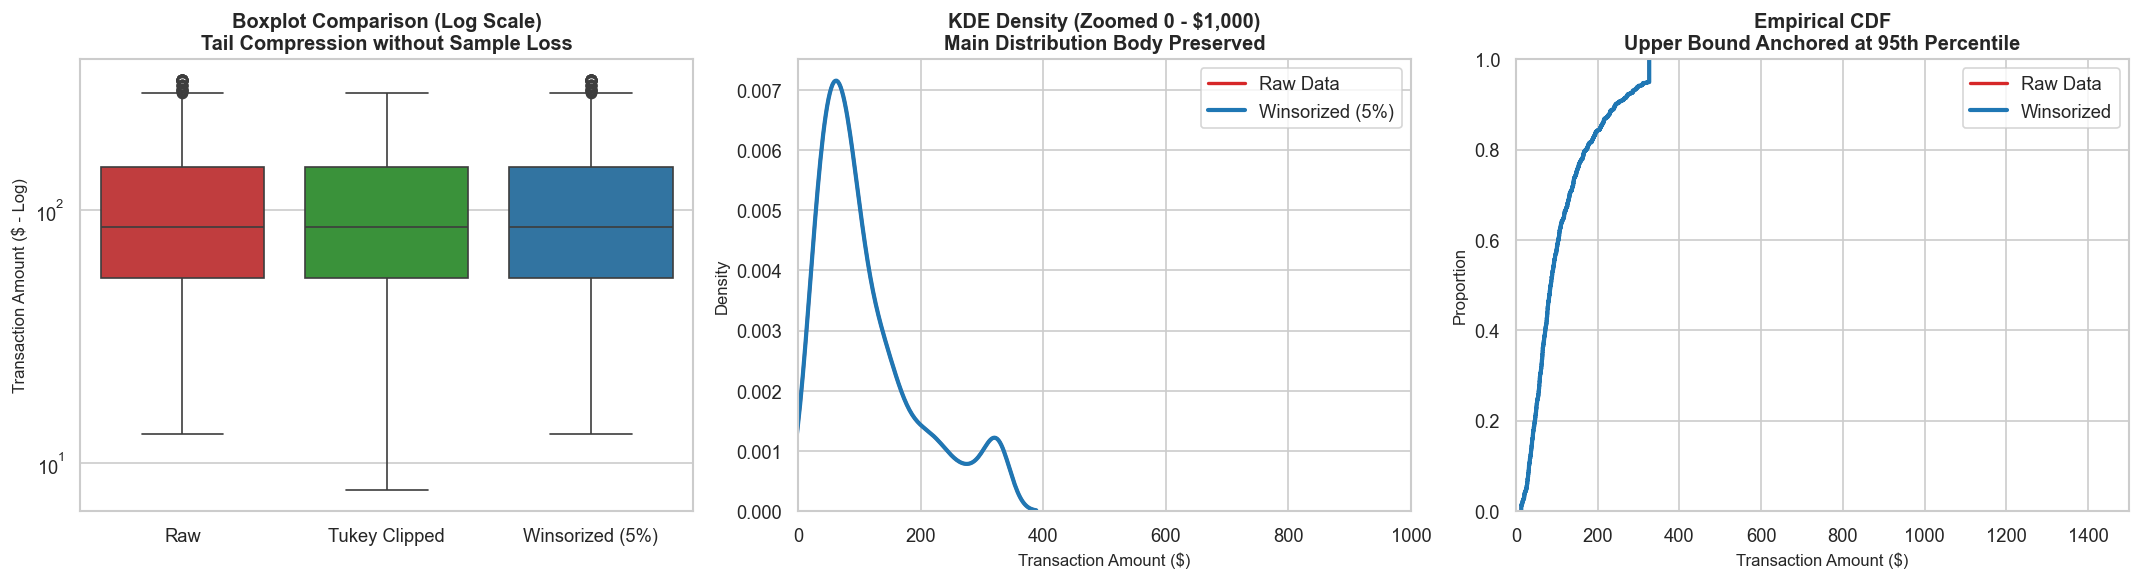

In [8]:
# 3.5 Visualizing Outlier Compression: Boxplots & Density Shapes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Boxplot comparison across strategies
sns.boxplot(data=df_tx[['raw_amount', 'tukey_clipped', 'winsorized_5pct']], 
            palette=['#d62728', '#2ca02c', '#1f77b4'], ax=axes[0])
axes[0].set_xticklabels(['Raw', 'Tukey Clipped', 'Winsorized (5%)'])
axes[0].set_yscale('log')
axes[0].set_title("Boxplot Comparison (Log Scale)\nTail Compression without Sample Loss", fontweight='bold')
axes[0].set_ylabel("Transaction Amount ($ - Log)")

# Panel 2: Density Distribution (Zoomed in on main density)
sns.kdeplot(df_tx['raw_amount'], ax=axes[1], label='Raw Data', color='#d62728', lw=2)
sns.kdeplot(df_tx['winsorized_5pct'], ax=axes[1], label='Winsorized (5%)', color='#1f77b4', lw=2.5)
axes[1].set_xlim(0, 1000)
axes[1].set_title("KDE Density (Zoomed 0 - $1,000)\nMain Distribution Body Preserved", fontweight='bold')
axes[1].set_xlabel("Transaction Amount ($)")
axes[1].legend()

# Panel 3: Empirical Cumulative Distribution Function (ECDF)
sns.ecdfplot(df_tx['raw_amount'], ax=axes[2], label='Raw Data', color='#d62728', lw=2)
sns.ecdfplot(df_tx['winsorized_5pct'], ax=axes[2], label='Winsorized', color='#1f77b4', lw=2.5)
axes[2].set_xlim(0, 1500)
axes[2].set_title("Empirical CDF\nUpper Bound Anchored at 95th Percentile", fontweight='bold')
axes[2].set_xlabel("Transaction Amount ($)")
axes[2].legend()

plt.tight_layout()
plt.show()

### ⚠️ Interview Traps & Viva Hacks (Outlier Treatment)

> [!WARNING]
> **Trap 5: Does symmetric Winsorization (e.g. 5% top and bottom) alter the sample median?**  
> **Viva Answer:** **No, the median remains exactly invariant.** Because Winsorization only replaces values outside the extreme percentiles ($5^{\text{th}}$ and $95^{\text{th}}$), the middle $50^{\text{th}}$ percentile is completely untouched as long as the trimming fraction $\alpha < 0.50$.

> [!WARNING]
> **Trap 6: When is it a catastrophic business mistake to clip or winsorize outliers?**  
> **Viva Answer:** In **Fraud Detection**, **Cybersecurity Intrusion Detection**, and **High-Risk Insurance Claims**. In these domains, the outliers are not noise—they represent the actual rare target events you are attempting to detect! Capping them destroys the classification signal.

---

## 4. Duplicate Detection & Entity Resolution Basics

### 4.1 The Duplicate Taxonomy in Enterprise Systems
Duplicates arise from distributed data silos, CRM mergers, customer typos, and differing formatting standards.

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                                 Duplicate Hierarchy                                    │
├────────────────────────────┬───────────────────────────────────────────────────────────┤
│ 1. Exact Duplicate         │ Every single column is identical.                         │
│                            │ Handled via: df.drop_duplicates()                         │
├────────────────────────────┼───────────────────────────────────────────────────────────┤
│ 2. Primary Key / Subset    │ Key business identifiers match (e.g., PAN, SSN, Email).   │
│    Duplicate               │ Handled via: df.drop_duplicates(subset=['email'])          │
├────────────────────────────┼───────────────────────────────────────────────────────────┤
│ 3. Fuzzy / Near-Duplicate  │ Typos, abbreviations, word-order inversions.              │
│    (Entity Resolution)     │ e.g., 'Sundar Pichai' vs 'Sundar K. Pichai' vs 'Pichai, S'│
│                            │ Handled via: Fuzzy String Distance + Graph Clustering     │
└────────────────────────────┴───────────────────────────────────────────────────────────┘
```

---

### 4.2 String Distance Metrics & Sequence Matching
To determine if two string records refer to the same physical entity:
* **Levenshtein Distance:** Minimum number of single-character edits (insertions, deletions, substitutions) required to transform string $A$ into string $B$.
* **Gestalt Pattern Matching (`difflib.SequenceMatcher`):** Computes similarity ratio based on longest common contiguous matching sub-sequences:
  $$\text{Ratio} = \frac{2 \times M}{T}$$
  where $M$ is the number of matching characters and $T$ is the total length of both strings.

### 4.3 The $O(N^2)$ Scalability Trap & The "Blocking" Solution
If a customer database has $1,000,000$ records, calculating all pairwise string similarities requires:

$$\text{Comparisons} = \frac{N(N - 1)}{2} = \frac{10^6 \times 999,999}{2} \approx 5 \times 10^{11} \text{ comparisons!}$$

Even at 100,000 comparisons per second, this takes **over 57 days**!

```
THE BLOCKING TECHNIQUE:
Instead of comparing every record to every other record:
1. Generate a Blocking Key (e.g. State Code + First 2 letters of Last Name).
2. Group records by Blocking Key.
3. Perform fuzzy matching ONLY within each block!
Result: Reduces comparisons from 500 Billion to a few Thousand!
```

---

In [9]:
# 4.4 Enterprise Entity Resolution & Deduplication Pipeline
raw_customers = pd.DataFrame({
    'raw_name': [
        "Sundar Pichai",
        "Sundar K. Pichai",
        "Pichai, Sundar",
        "Satya Nadella",
        "Satya Naddela",
        "Satya H. Nadella",
        "Jensen Huang",
        "Jen-Hsun Huang",
        "Jensen M. Huang",
        "Tim Cook",
        "Timothy D. Cook"
    ],
    'company': [
        "Google", "Google LLC", "Alphabet",
        "Microsoft", "Microsoft Corp", "MSFT",
        "Nvidia", "NVIDIA Corp", "Nvidia",
        "Apple", "Apple Inc"
    ],
    'city': [
        "Mountain View", "Mountain View", "Mountain View",
        "Redmond", "Redmond", "Redmond",
        "Santa Clara", "Santa Clara", "Santa Clara",
        "Cupertino", "Cupertino"
    ]
})

# Step 1: Text Sanitization & Standardization
def clean_entity_string(s: str) -> str:
    s = s.lower().strip()
    s = s.replace(",", " ").replace(".", "")
    # Standardize corporate suffixes
    s = s.replace("corp", "").replace("llc", "").replace("inc", "")
    return " ".join(s.split())

raw_customers['clean_name'] = raw_customers['raw_name'].apply(clean_entity_string)

# Step 2: Compute Pairwise Similarity Matrix using difflib
n_entities = len(raw_customers)
sim_matrix = np.zeros((n_entities, n_entities))

for i in range(n_entities):
    for j in range(n_entities):
        s1 = raw_customers.loc[i, 'clean_name']
        s2 = raw_customers.loc[j, 'clean_name']
        # Token sort ratio to handle inverted names ('pichai sundar' vs 'sundar pichai')
        tokens1 = " ".join(sorted(s1.split()))
        tokens2 = " ".join(sorted(s2.split()))
        sim = difflib.SequenceMatcher(None, tokens1, tokens2).ratio()
        sim_matrix[i, j] = sim

# Step 3: Entity Clustering via Connected Components (Threshold = 0.72)
similarity_threshold = 0.72
adjacency = sim_matrix >= similarity_threshold

# Disjoint Set Union (Connected Components) to assign Canonical Entity IDs
visited = set()
canonical_ids = np.zeros(n_entities, dtype=int)
current_cluster = 1

for i in range(n_entities):
    if i not in visited:
        # Find all nodes connected to node i
        cluster_members = np.where(adjacency[i])[0]
        for m in cluster_members:
            visited.add(m)
            canonical_ids[m] = current_cluster
        current_cluster += 1

raw_customers['canonical_entity_id'] = canonical_ids

# Canonical Name Resolution (Select the most frequent or clean name per cluster)
canonical_name_map = raw_customers.groupby('canonical_entity_id')['raw_name'].first()
raw_customers['resolved_canonical_name'] = raw_customers['canonical_entity_id'].map(canonical_name_map)

print("=" * 80)
print("RESOLVED ENTERPRISE CRM ENTITY RESOLUTION AUDIT")
print("=" * 80)
display_cols = ['raw_name', 'company', 'canonical_entity_id', 'resolved_canonical_name']
print(raw_customers[display_cols].to_string(index=False))

RESOLVED ENTERPRISE CRM ENTITY RESOLUTION AUDIT
        raw_name        company  canonical_entity_id resolved_canonical_name
   Sundar Pichai         Google                    1           Sundar Pichai
Sundar K. Pichai     Google LLC                    1           Sundar Pichai
  Pichai, Sundar       Alphabet                    1           Sundar Pichai
   Satya Nadella      Microsoft                    2           Satya Nadella
   Satya Naddela Microsoft Corp                    2           Satya Nadella
Satya H. Nadella           MSFT                    2           Satya Nadella
    Jensen Huang         Nvidia                    3            Jensen Huang
  Jen-Hsun Huang    NVIDIA Corp                    3            Jensen Huang
 Jensen M. Huang         Nvidia                    3            Jensen Huang
        Tim Cook          Apple                    4                Tim Cook
 Timothy D. Cook      Apple Inc                    4                Tim Cook


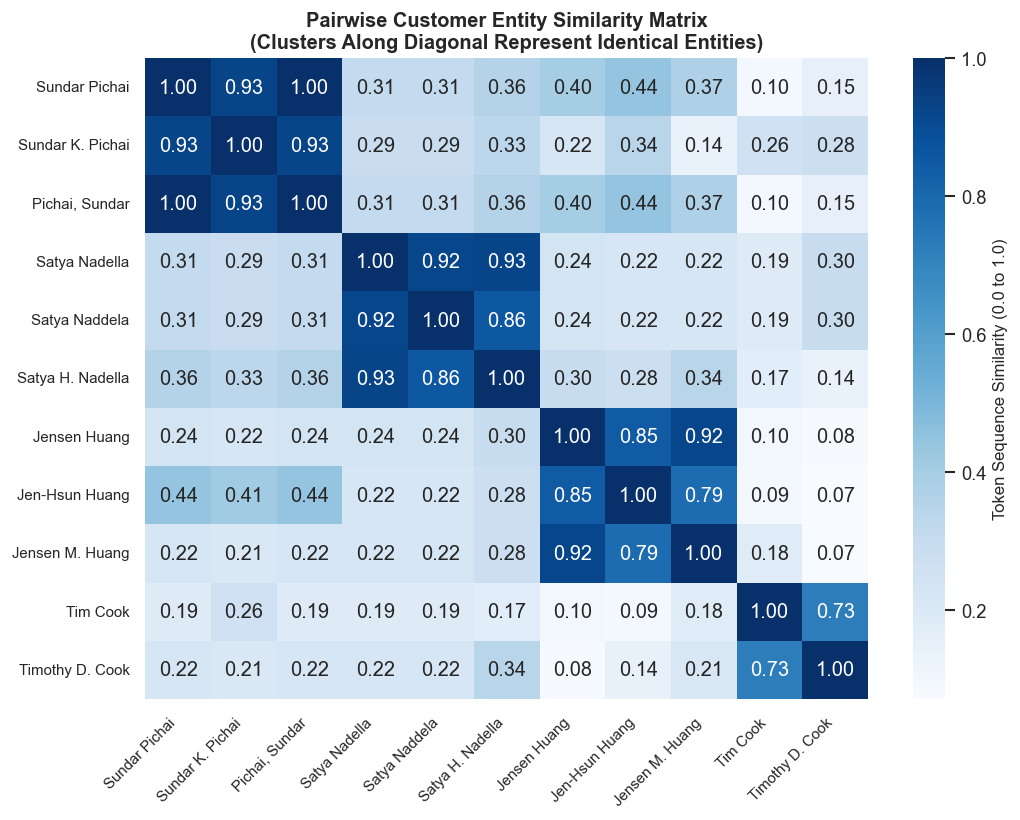

In [10]:
# 4.5 Visualizing Entity Resolution: Pairwise Similarity Matrix Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="Blues", 
            xticklabels=raw_customers['raw_name'], 
            yticklabels=raw_customers['raw_name'],
            cbar_kws={'label': 'Token Sequence Similarity (0.0 to 1.0)'})
plt.title("Pairwise Customer Entity Similarity Matrix\n(Clusters Along Diagonal Represent Identical Entities)", fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

### ⚠️ Interview Traps & Viva Hacks (Entity Resolution)

> [!WARNING]
> **Trap 7: Why is running pairwise string distance directly on 1 Million rows fatal?**  
> **Viva Answer:** Because the comparison complexity is $\mathcal{O}(N^2)$ (500 Billion comparisons). In production enterprise systems, you must always implement a **Blocking Pass** (e.g. hash on `Zip_Code + Soundex(Last_Name)` or Locality-Sensitive Hashing - LSH) to restrict comparisons strictly to probable candidates within the same block.

> [!WARNING]
> **Trap 8: Exact deduplication before or after text normalization?**  
> **Viva Answer:** Always run string normalization (**lowercase**, **trim whitespace**, **strip punctuation**, **expand abbreviations**) **BEFORE** running exact deduplication (`df.drop_duplicates()`). Otherwise, `'IBM'` and `'ibm '` will falsely register as separate unique entities.

---

## 5. Summary Comparison Scorecard & Viva Flashcards

### 5.1 Architecture & Strategy Decision Matrix

| Dimension | Primary Technique | Mathematical Guarantee / Behavior | Best Suited Scenario |
| :--- | :--- | :--- | :--- |
| **Missing Taxonomy** | **MCAR vs MAR vs MNAR** | MCAR allows deletion; MAR requires conditioned imputation; MNAR requires sensitivity modeling | Clinical trials, survey auditing, finance logs |
| **KNN Imputation** | Euclidean Distance on Scaled Vectors | Imputes local cluster consensus; preserves local manifold | Tabular data with non-linear relationships ($D < 20$) |
| **Iterative (MICE)** | Chained Round-Robin Regression | Preserves multivariate covariance $\Sigma$ and correlations | Multi-column datasets with strong linear dependencies |
| **Rolling Imputation** | Forward-Fill (`ffill`) / Moving Median | Eliminates Lookahead Bias; maintains temporal causal sequence | Real-time streaming, algorithmic trading, IoT sensors |
| **Winsorization** | Percentile Capping ($5^{\text{th}}$ and $95^{\text{th}}$) | Leaves sample size $N$ intact; median invariant; reduces tail variance | Financial transactions, regression feature preprocessing |
| **Entity Resolution** | Blocking + Token Similarity | Slashes $\mathcal{O}(N^2)$ comparison overhead; unifies dirty records | CRM consolidation, Master Data Management (MDM) |

---

### ⚡ Quick-Fire Interview Flashcards
| Interview Question | 1-Line Punchy Answer |
| :--- | :--- |
| **What test checks for MCAR?** | Little's MCAR Test (tests if observed vs missing means differ significantly). |
| **Why is mean imputation discouraged?** | Artificially deflates variance ($\sigma^2 \downarrow$) and collapses inter-variable correlations toward zero. |
| **What happens if you run KNN without scaling?** | Columns with large absolute magnitudes (e.g., Salary) dominate distance calculations. |
| **Does Winsorization change the sample median?** | No, as long as less than 50% of either tail is winsorized. |
| **How does Blocking speed up entity resolution?** | Converts $\mathcal{O}(N^2)$ global comparisons into localized within-block comparisons. |
| **Why is `bfill` dangerous in financial pipelines?** | Introduces Lookahead Bias by leaking future values into historical timestamps. |

---
**Module Completed:** Day 9 Part 2 — Data Cleaning, Imputation & Entity Resolution  
**Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)
